# SemEval 2025 Task 9: Food Hazard Detection – baseline (1. etapa)

**Úloha:** z hlásenia o sťahovaní potraviny z trhu určiť
- **ST1:** kategóriu nebezpečenstva (`hazard-category`, 10 tried) a kategóriu produktu (`product-category`, 22 tried),
- **ST2:** presné nebezpečenstvo (`hazard`, 128 tried) a presný produkt (`product`, vyše 1 000 tried).

**Baseline:** TF-IDF (z cvičenia 3) + logistická regresia (z cvičenia 2). Pre porovnanie aj lineárny SVM.

**Postup:**
1. načítanie dát a ich analýza,
2. tokenizácia a TF-IDF,
3. výber vstupu (titulok / text / oboje) a váženia tried na **validačnej** množine,
4. konečné vyhodnotenie na **testovacej** množine oficiálnou metrikou,
5. ukážka predikcie pre nový záznam.

Celý notebook beží na CPU. Na 4-jadrovom počítači trvá približne 5–6 minút, najdlhšie trénovanie logistickej regresie pre 1 000 produktov. V datalabe to môže byť o niečo dlhšie.

## 0. Importy
Rovnaké knižnice ako v cvičeniach 2 a 3.

In [1]:
import re, os, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.multiclass import OneVsRestClassifier
from sklearn.svm import LinearSVC
from sklearn.dummy import DummyClassifier
from sklearn.metrics import f1_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

SEED = 42                       # pevné číslo -> rovnaké výsledky pri každom spustení
np.random.seed(SEED)

## 1. Načítanie dát

Dáta sú z oficiálneho repozitára úlohy. Ak súbory `incidents_train.csv`, `incidents_valid.csv` a `incidents_test.csv` ležia v tom istom priečinku ako notebook, v podpriečinku `data/` alebo v `../data/` (štruktúra repozitára), načítajú sa odtiaľ. Inak sa stiahnu z GitHubu.

- **train** (5 082): na tom sa model učí,
- **valid** (565): na tom vyberáme nastavenia (ako „skúška nanečisto“),
- **test** (997): použijeme **iba raz**, na konečné vyhodnotenie. Keby sme podľa testu ladili nastavenia, výsledok by bol prikrášlený.

In [2]:
URL = "https://raw.githubusercontent.com/food-hazard-detection-semeval-2025/food-hazard-detection-semeval-2025.github.io/main/data/"

def nacitaj(nazov):
    subor = f"{nazov}.csv"
    for cesta in [subor, os.path.join("data", subor), os.path.join("..", "data", subor)]:
        if os.path.exists(cesta):      # pri notebooku, v data/ alebo v ../data/
            return pd.read_csv(cesta)
    return pd.read_csv(URL + subor)    # inak ho stiahneme

train = nacitaj("incidents_train")
valid = nacitaj("incidents_valid")
test  = nacitaj("incidents_test")
print("train:", train.shape, " valid:", valid.shape, " test:", test.shape)
train[["title", "hazard-category", "product-category", "hazard", "product"]].head()

train: (5082, 11)  valid: (565, 11)  test: (997, 11)


,title,hazard-category,product-category,hazard,product
0,Recall Notification: FSIS-024-94,biological,"meat, egg and dairy products",listeria monocytogenes,smoked sausage
1,Recall Notification: FSIS-033-94,biological,"meat, egg and dairy products",listeria spp,sausage
2,Recall Notification: FSIS-014-94,biological,"meat, egg and dairy products",listeria monocytogenes,ham slices
3,Recall Notification: FSIS-009-94,foreign bodies,"meat, egg and dairy products",plastic fragment,thermal processed pork meat
4,Recall Notification: FSIS-001-94,foreign bodies,"meat, egg and dairy products",plastic fragment,chicken breast


## 2. Analýza dát

Pozrieme sa, koľko tried má každý label a ako sú rozložené. Toto je dôležité pre výber metriky.

In [3]:
LABELY = ["hazard-category", "product-category", "hazard", "product"]
for lab in LABELY:
    pocty = train[lab].value_counts()
    print(f"{lab:18s} tried: {len(pocty):5d}   najčastejšia: {pocty.iloc[0]:5d}   "
          f"tried s menej ako 5 príkladmi: {(pocty < 5).sum()}")

hazard-category    tried:    10   najčastejšia:  1854   tried s menej ako 5 príkladmi: 1
product-category   tried:    22   najčastejšia:  1434   tried s menej ako 5 príkladmi: 0
hazard             tried:   128   najčastejšia:   665   tried s menej ako 5 príkladmi: 42
product            tried:  1022   najčastejšia:   185   tried s menej ako 5 príkladmi: 777


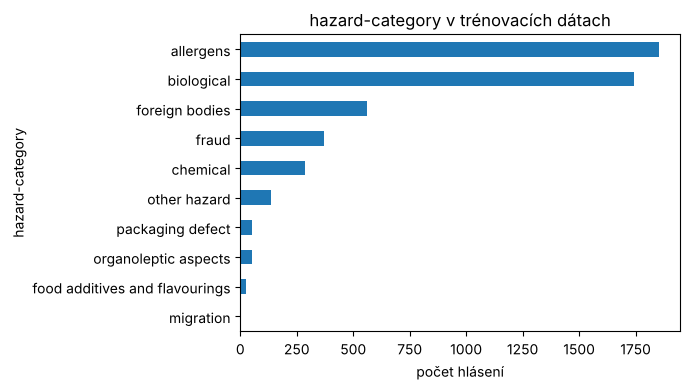

In [4]:
pocty = train["hazard-category"].value_counts()
pocty.plot(kind="barh", figsize=(7, 4), title="hazard-category v trénovacích dátach")
plt.gca().invert_yaxis(); plt.xlabel("počet hlásení"); plt.tight_layout(); plt.show()

In [5]:
dlzka_titulku = train["title"].str.split().str.len()
dlzka_textu   = train["text"].str.split().str.len()
print("titulok: priemer %.0f slov" % dlzka_titulku.mean())
print("text:    medián %.0f slov, maximum %d" % (dlzka_textu.median(), dlzka_textu.max()))

titulok: priemer 13 slov
text:    medián 306 slov, maximum 8406


**Čo z toho vyplýva:**
- Triedy sú **veľmi nevyvážené** (napr. *allergens* 1 854-krát, *migration* 3-krát). Accuracy by bola zavádzajúca, preto sa používa **macro-F1**: F1 sa vypočíta pre každú triedu zvlášť a spriemeruje sa, takže každá trieda má rovnakú váhu.
- Pri `product` má veľa tried len 1–2 príklady. Model ich takmer nemá z čoho naučiť, preto bude ST2 oveľa ťažšia.
- Titulok je krátky, text dlhý. Vyskúšame, čo funguje lepšie.

## 3. Oficiálna metrika

Podľa organizátorov:
1. vypočíta sa macro-F1 pre **hazard**,
2. vypočíta sa macro-F1 pre **produkt**, ale **iba na hláseniach, kde bol hazard predikovaný správne**,
3. výsledok je ich priemer.

Hazard je teda dôležitejší: ak je hazard zle, produkt sa vôbec nepočíta.

In [6]:
def oficialne_skore(hazard_true, product_true, hazard_pred, product_pred):
    hazard_true, product_true = np.asarray(hazard_true), np.asarray(product_true)
    hazard_pred, product_pred = np.asarray(hazard_pred), np.asarray(product_pred)
    f1_hazard = f1_score(hazard_true, hazard_pred, average="macro")
    spravny_hazard = hazard_pred == hazard_true                    # maska: kde hazard sedí
    f1_product = f1_score(product_true[spravny_hazard], product_pred[spravny_hazard], average="macro")
    return (f1_hazard + f1_product) / 2

def vyhodnot(data, pred):
    # pred = slovník {label: predikcie}
    st1 = oficialne_skore(data["hazard-category"], data["product-category"],
                          pred["hazard-category"], pred["product-category"])
    st2 = oficialne_skore(data["hazard"], data["product"], pred["hazard"], pred["product"])
    vysl = {"ST1": st1, "ST2": st2}
    for lab in pred:
        vysl[lab] = f1_score(data[lab], pred[lab], average="macro")
    return vysl

## 4. Tokenizácia a TF-IDF

- **Tokenizer** je ten istý regulárny výraz ako v cvičení 1: slovo alebo číslo (`\w+`), alebo jeden znak interpunkcie (`[^\w\s]`). Všetko prevedieme na malé písmená.
- **TF-IDF** ako v cvičení 3. `sublinear_tf=True` znamená **logaritmickú TF** (1 + log f), ktorá v cvičení 3 vyšla najlepšie. IDF je vyhladená (štandard v scikit-learn).
- `min_df=2`: slovo, ktoré je iba v jednom hlásení, vynecháme. Zmenší to slovník a odstráni preklepy.
- IDF sa počíta **iba z trénovacích dát** (`fit` na train, `transform` na valid/test), aby nedošlo k úniku informácií (data leakage), o ktorom sme hovorili v cvičení 3.

In [7]:
TOKEN_REGEX = re.compile(r"\w+|[^\w\s]")

def tokenizuj(text):
    return TOKEN_REGEX.findall(text.lower())

def vstup(data, pole):
    # pole: "title", "text" alebo "title+text"
    if pole == "title":
        return data["title"]
    if pole == "text":
        return data["text"]
    return data["title"] + " " + data["text"]

def tfidf(pole):
    vec = TfidfVectorizer(tokenizer=tokenizuj, token_pattern=None, lowercase=False,
                          sublinear_tf=True, min_df=2)
    X_train = vec.fit_transform(vstup(train, pole))   # slovník + IDF iba z train
    X_valid = vec.transform(vstup(valid, pole))
    X_test  = vec.transform(vstup(test, pole))
    return vec, X_train, X_valid, X_test

print(tokenizuj("Recall: Peanut butter (16 oz) may contain Salmonella!"))

['recall', ':', 'peanut', 'butter', '(', '16', 'oz', ')', 'may', 'contain', 'salmonella', '!']


## 5. Modely

**Logistická regresia** (cvičenie 2): každé slovo má pre každú triedu váhu. Pri 1 000 produktoch je klasická (multinomiálna) verzia veľmi pomalá, preto použijeme **one-vs-rest**: pre každú triedu sa natrénuje samostatný binárny model „je to táto trieda, alebo nie?“ a vyhrá trieda s najvyššou pravdepodobnosťou.

- `C=10`: slabšia regularizácia. Pri TF-IDF sú hodnoty malé (pod 1), a ako sme videli pri relatívnej TF v cvičení 3, silná regularizácia by modelu nedovolila naučiť sa dosť veľké váhy.
- `class_weight="balanced"`: chyba na zriedkavej triede sa počíta viac. Pomáha to zriedkavým triedam, čo pri macro-F1 zvyšuje skóre.

**Lineárny SVM** je podobný lineárny model, ktorý hľadá hranicu s čo najväčším odstupom medzi triedami. Je oveľa rýchlejší a v článku autorov datasetu (CICLe) patril k najlepším klasickým modelom, preto ho pridávame na porovnanie.

**Majoritný klasifikátor** vždy povie najčastejšiu triedu. Je to spodná hranica: lepší musí byť každý zmysluplný model.

In [8]:
def model_lr(vahy=None):
    return OneVsRestClassifier(LogisticRegression(solver="liblinear", C=10, class_weight=vahy))

def model_svm(vahy=None):
    return LinearSVC(C=1.0, class_weight=vahy, random_state=SEED)

def natrenuj_a_predikuj(tvorca, X_tr, X_ev, labely=LABELY):
    pred, modely = {}, {}
    for lab in labely:
        model = tvorca()
        model.fit(X_tr, train[lab])
        pred[lab] = model.predict(X_ev)
        modely[lab] = model              # model si odložíme, použijeme ho pri novom zázname
    return pred, modely

## 6. Výber nastavení na validačnej množine

Porovnáme 3 vstupy × 2 spôsoby váženia tried.

- **Lineárny SVM** stihneme na všetkých 4 labeloch, takže dostaneme ST1 aj ST2.
- **Logistickú regresiu** pre čas porovnávame iba na ST1 (2 labely s 10 a 22 triedami). Pre celé ST2 ju spustíme až s vybraným nastavením v kroku 7.

In [9]:
POLIA = ["title", "text", "title+text"]
VAHY = [None, "balanced"]
matice = {pole: tfidf(pole) for pole in POLIA}
for pole in POLIA:
    print(f"{pole:11s} veľkosť slovníka: {len(matice[pole][0].vocabulary_)}")

title       veľkosť slovníka: 3468
text        veľkosť slovníka: 15087
title+text  veľkosť slovníka: 15180


In [10]:
riadky = []
for pole in POLIA:
    _, X_tr, X_va, _ = matice[pole]
    for v in VAHY:
        t = time.time()
        p, _ = natrenuj_a_predikuj(lambda: model_svm(v), X_tr, X_va)
        r = vyhodnot(valid, p)
        riadky.append({"model": "SVM", "vstup": pole, "váhy tried": v or "žiadne", **r,
                       "čas [s]": round(time.time() - t)})
        t = time.time()
        p, _ = natrenuj_a_predikuj(lambda: model_lr(v), X_tr, X_va, ["hazard-category", "product-category"])
        st1 = oficialne_skore(valid["hazard-category"], valid["product-category"],
                              p["hazard-category"], p["product-category"])
        riadky.append({"model": "LR", "vstup": pole, "váhy tried": v or "žiadne", "ST1": st1,
                       "hazard-category": f1_score(valid["hazard-category"], p["hazard-category"], average="macro"),
                       "product-category": f1_score(valid["product-category"], p["product-category"], average="macro"),
                       "čas [s]": round(time.time() - t)})
porovnanie = pd.DataFrame(riadky)
porovnanie.round(3)

,model,vstup,váhy tried,ST1,ST2,hazard-category,product-category,hazard,product,čas [s]
0,SVM,title,žiadne,0.681,0.387,0.662,0.655,0.458,0.268,5
1,LR,title,žiadne,0.693,NaN,0.663,0.673,NaN,NaN,0
2,SVM,title,balanced,0.633,0.327,0.630,0.600,0.389,0.205,5
3,LR,title,balanced,0.686,NaN,0.681,0.628,NaN,NaN,1
4,SVM,text,žiadne,0.705,0.410,0.724,0.702,0.560,0.237,21
5,LR,text,žiadne,0.684,NaN,0.704,0.626,NaN,NaN,3
6,SVM,text,balanced,0.717,0.393,0.773,0.679,0.577,0.191,22
7,LR,text,balanced,0.697,NaN,0.740,0.684,NaN,NaN,5
8,SVM,title+text,žiadne,0.731,0.429,0.760,0.722,0.586,0.247,20
9,LR,title+text,žiadne,0.707,NaN,0.725,0.650,NaN,NaN,3


In [11]:
najlepsie = porovnanie[porovnanie.model == "SVM"].sort_values("ST1", ascending=False).iloc[0]
print("Najlepšie nastavenie SVM podľa ST1 na validácii:", najlepsie["vstup"], "/", najlepsie["váhy tried"])
najlepsie_lr = porovnanie[porovnanie.model == "LR"].sort_values("ST1", ascending=False).iloc[0]
print("Najlepšie nastavenie LR  podľa ST1 na validácii:", najlepsie_lr["vstup"], "/", najlepsie_lr["váhy tried"])

Najlepšie nastavenie SVM podľa ST1 na validácii: title+text / balanced
Najlepšie nastavenie LR  podľa ST1 na validácii: title+text / balanced


**Ako čítať tabuľku:** stĺpce ST1 a ST2 sú oficiálne skóre, ostatné sú macro-F1 jednotlivých labelov. Stĺpec *čas* nie je porovnateľný medzi modelmi: SVM sa tu trénuje na 4 labeloch, LR iba na 2. Porovnateľné časy sú v kroku 7. Hľadáme riadok s najvyšším ST1 (hlavné poradie súťaže). Nastavenie vyberáme **podľa validácie**, nie podľa testu.

## 7. Konečné vyhodnotenie na testovacej množine

S vybraným nastavením natrénujeme modely na train a raz ich vyhodnotíme na test.

Pre **férové porovnanie s organizátormi** vyhodnotíme aj modely, ktoré vidia **iba titulok**. Organizátori totiž svoj baseline (TF-IDF + LR: ST1 0,498, ST2 0,183; BERT: ST1 0,667, ST2 0,165) trénovali iba na titulku. Pre variant „iba titulok“ berieme váženie tried, ktoré bolo na validácii najlepšie pre titulok.

Pri každom modeli meriame čas trénovania a predikcie všetkých 4 labelov.

In [12]:
def nastavenie(riadok):
    return riadok["vstup"], (None if riadok["váhy tried"] == "žiadne" else "balanced")

def najlepsi_riadok(model, pole=None):
    r = porovnanie[porovnanie.model == model]
    if pole is not None:
        r = r[r.vstup == pole]
    return r.sort_values("ST1", ascending=False).iloc[0]

vysledky, casy, predikcie, modely = {}, {}, {}, {}

def spusti(nazov, tvorca, pole):
    _, X_tr, _, X_te = matice[pole]
    t = time.time()
    pred, mod = natrenuj_a_predikuj(tvorca, X_tr, X_te)
    casy[nazov] = round(time.time() - t)
    vysledky[nazov] = vyhodnot(test, pred)
    predikcie[nazov], modely[nazov] = pred, mod

# spodná hranica
spusti("Majoritná trieda", lambda: DummyClassifier(strategy="most_frequent"), "title")

# najlepšie nastavenia z validácie (titulok + text)
pole, v = nastavenie(najlepsi_riadok("SVM"))
spusti(f"SVM ({pole}, {v or 'bez váh'})", lambda: model_svm(v), pole)
pole_lr, v_lr = nastavenie(najlepsi_riadok("LR"))
spusti(f"LR ({pole_lr}, {v_lr or 'bez váh'})", lambda: model_lr(v_lr), pole_lr)

# iba titulok – rovnaký vstup ako baseline organizátorov
_, v_t = nastavenie(najlepsi_riadok("SVM", "title"))
spusti(f"SVM (title, {v_t or 'bez váh'})", lambda: model_svm(v_t), "title")
_, v_tl = nastavenie(najlepsi_riadok("LR", "title"))
spusti(f"LR (title, {v_tl or 'bez váh'})", lambda: model_lr(v_tl), "title")

NAZOV_SVM = f"SVM ({pole}, {v or 'bez váh'})"
NAZOV_LR = f"LR ({pole_lr}, {v_lr or 'bez váh'})"
pred_svm, pred_lr, modely_lr = predikcie[NAZOV_SVM], predikcie[NAZOV_LR], modely[NAZOV_LR]

tabulka = pd.DataFrame(vysledky).T[["ST1", "ST2"] + LABELY]
tabulka["čas [s]"] = pd.Series(casy)
tabulka.round(3)

,ST1,ST2,hazard-category,product-category,hazard,product,čas [s]
Majoritná trieda,0.035,0.001,0.054,0.022,0.002,0.000,0
"SVM (title+text, balanced)",0.723,0.410,0.763,0.682,0.585,0.220,21
"LR (title+text, balanced)",0.717,0.406,0.743,0.692,0.555,0.247,112
"SVM (title, bez váh)",0.663,0.363,0.638,0.683,0.426,0.260,5
"LR (title, bez váh)",0.633,0.329,0.600,0.664,0.358,0.247,13


Výsledky uložíme do `results/summary.csv`, aby sa čísla v správe dali skontrolovať bez spúšťania notebooku.

In [13]:
os.makedirs("results", exist_ok=True)
tabulka.round(4).to_csv("results/summary.csv", index_label="model")
print(open("results/summary.csv").read())

model,ST1,ST2,hazard-category,product-category,hazard,product,čas [s]
Majoritná trieda,0.0352,0.0014,0.0536,0.022,0.0021,0.0002,0
"SVM (title+text, balanced)",0.7225,0.4097,0.7631,0.6825,0.585,0.2202,21
"LR (title+text, balanced)",0.717,0.4063,0.7431,0.6917,0.5551,0.2472,112
"SVM (title, bez váh)",0.6634,0.3631,0.6382,0.683,0.4261,0.2596,5
"LR (title, bez váh)",0.6335,0.3285,0.5999,0.6645,0.3575,0.2469,13



**Je rozdiel medzi SVM a LR náhodný?** Testovacia množina má iba 997 hlásení. Pomocou *bootstrapu* ju 1 000-krát náhodne prevzorkujeme (s opakovaním), zakaždým vypočítame skóre a z rozdelenia výsledkov určíme 95 % interval spoľahlivosti.

In [14]:
def bootstrap(pred, n=1000):
    rng = np.random.default_rng(SEED)
    st1, st2 = [], []
    idx_all = np.arange(len(test))
    for _ in range(n):
        idx = rng.choice(idx_all, size=len(idx_all), replace=True)
        d = test.iloc[idx]
        st1.append(oficialne_skore(d["hazard-category"], d["product-category"],
                                   pred["hazard-category"][idx], pred["product-category"][idx]))
        st2.append(oficialne_skore(d["hazard"], d["product"], pred["hazard"][idx], pred["product"][idx]))
    return np.percentile(st1, [2.5, 97.5]), np.percentile(st2, [2.5, 97.5])

for nazov in [NAZOV_SVM, NAZOV_LR]:
    i1, i2 = bootstrap(predikcie[nazov])
    print(f"{nazov:28s} ST1 95 % interval: {i1[0]:.3f}–{i1[1]:.3f}   ST2: {i2[0]:.3f}–{i2[1]:.3f}")

SVM (title+text, balanced)   ST1 95 % interval: 0.680–0.791   ST2: 0.384–0.436


LR (title+text, balanced)    ST1 95 % interval: 0.674–0.793   ST2: 0.392–0.444


Ak sa intervaly dvoch modelov výrazne prekrývajú, rozdiel medzi nimi nemôžeme považovať za preukázaný.

## 8. Podklady pre chybovú analýzu

Tieto výpočty sú podkladom pre kapitolu o chybovej analýze. Komentáre k chybám dopĺňa tím.

### 8.1 Ukážka predikcií
Predikované triedy pre prvých 10 testovacích hlásení (model LR).

In [15]:
ukazka = pd.DataFrame({
    "titulok": test["title"].str[:60],
    "skutočný hazard": test["hazard-category"],
    "predikovaný hazard": pred_lr["hazard-category"],
    "skutočný produkt": test["product-category"],
    "predikovaný produkt": pred_lr["product-category"],
}).head(10)
ukazka

,titulok,skutočný hazard,predikovaný hazard,skutočný produkt,predikovaný produkt
0,Recall Notification: FSIS-039-94,biological,biological,"meat, egg and dairy products","meat, egg and dairy products"
1,Recall Notification: FSIS-026-95,biological,biological,fruits and vegetables,"meat, egg and dairy products"
2,Recall Notification: FSIS-028-95,biological,biological,"meat, egg and dairy products","meat, egg and dairy products"
3,Black & Gold—Sliced Silverside 250g,biological,biological,"meat, egg and dairy products","meat, egg and dairy products"
4,Nestle—Peters—Neapolitan Ice Cream,foreign bodies,foreign bodies,ices and desserts,ices and desserts
5,Knispel Fruit Juices—Chilled Fruit Juice,biological,biological,non-alcoholic beverages,non-alcoholic beverages
6,Woolworths Limited—Cheese King baked ricotta,biological,biological,"meat, egg and dairy products","meat, egg and dairy products"
7,West Coast Halal Meat Specialists—Halal Sliced...,biological,biological,"meat, egg and dairy products","meat, egg and dairy products"
8,Leggos—Stir Through pasta sauces,foreign bodies,foreign bodies,"soups, broths, sauces and condiments","soups, broths, sauces and condiments"
9,Brisbane Fish Markets—Queenfish,chemical,biological,seafood,seafood


### 8.2 Report po triedach pre `hazard-category`
Precision, recall a F1 pre každú triedu. Zriedkavé triedy (malý *support*) mávajú najnižšie F1 a práve tie ťahajú macro-F1 dole.

In [16]:
for nazov in [NAZOV_LR, NAZOV_SVM]:
    print(nazov)
    print(classification_report(test["hazard-category"], predikcie[nazov]["hazard-category"], zero_division=0))

LR (title+text, balanced)
                                precision    recall  f1-score   support

                     allergens       0.95      0.98      0.96       365
                    biological       0.98      0.98      0.98       343
                      chemical       0.98      0.90      0.94        52
food additives and flavourings       0.75      0.75      0.75         4
                foreign bodies       0.93      0.97      0.95       111
                         fraud       0.81      0.75      0.78        75
                     migration       0.00      0.00      0.00         1
          organoleptic aspects       0.78      0.70      0.74        10
                  other hazard       0.71      0.58      0.64        26
              packaging defect       0.56      0.90      0.69        10

                      accuracy                           0.94       997
                     macro avg       0.75      0.75      0.74       997
                  weighted avg      

### 8.3 Matica zámen pre `hazard-category`
Riadky sú skutočné triedy, stĺpce predikované. Čísla mimo diagonály sú chyby.

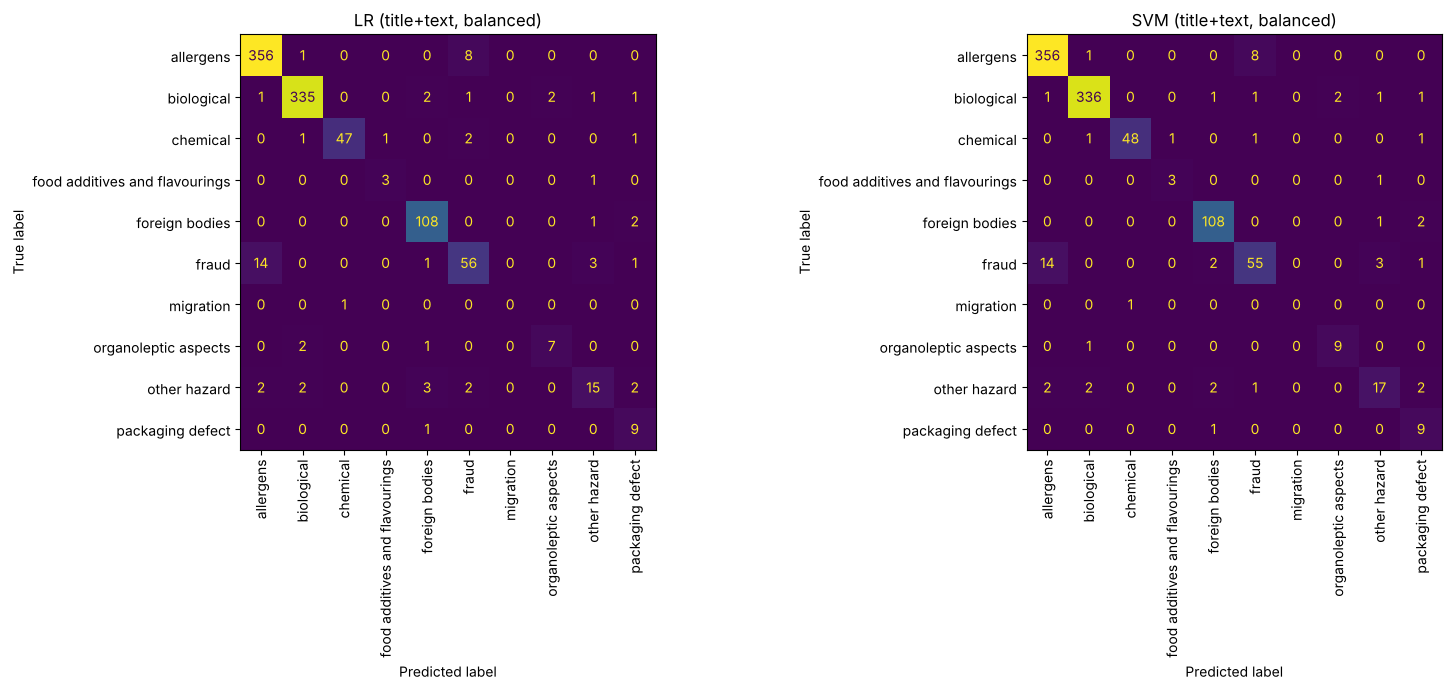

In [17]:
triedy = sorted(train["hazard-category"].unique())
fig, osi = plt.subplots(1, 2, figsize=(16, 7))
for os_, nazov in zip(osi, [NAZOV_LR, NAZOV_SVM]):
    cm = confusion_matrix(test["hazard-category"], predikcie[nazov]["hazard-category"], labels=triedy)
    ConfusionMatrixDisplay(cm, display_labels=triedy).plot(ax=os_, xticks_rotation=90, colorbar=False)
    os_.set_title(nazov)
plt.tight_layout(); plt.show()

### 8.4 Najčastejšie zamieňané dvojice tried

In [18]:
for nazov in [NAZOV_LR, NAZOV_SVM]:
    chyby = pd.DataFrame({"skutočná": test["hazard-category"], "predikovaná": predikcie[nazov]["hazard-category"]})
    chyby = chyby[chyby["skutočná"] != chyby["predikovaná"]]
    print(nazov, "– počet chýb:", len(chyby))
    print(chyby.value_counts().head(8).to_string(), "\n")

LR (title+text, balanced) – počet chýb: 61
skutočná        predikovaná         
fraud           allergens               14
allergens       fraud                    8
other hazard    foreign bodies           3
fraud           other hazard             3
biological      foreign bodies           2
other hazard    allergens                2
biological      organoleptic aspects     2
foreign bodies  packaging defect         2 

SVM (title+text, balanced) – počet chýb: 56
skutočná        predikovaná         
fraud           allergens               14
allergens       fraud                    8
fraud           other hazard             3
                foreign bodies           2
other hazard    allergens                2
biological      organoleptic aspects     2
foreign bodies  packaging defect         2
other hazard    packaging defect         2 



### 8.5 Chyby na okomentovanie
20 náhodne vybraných chýb modelu LR v `hazard-category`. Uložia sa do `results/chyby_hazard_category.csv` s prázdnym stĺpcom *komentár*, ktorý vyplní tím (napr. „titulok neobsahuje informáciu“, „podobné triedy“, „chyba v anotácii“).

In [19]:
maska = test["hazard-category"].values != pred_lr["hazard-category"]
chyby = pd.DataFrame({
    "title": test["title"], "text_zaciatok": test["text"].str[:300],
    "skutocna": test["hazard-category"], "predikovana": pred_lr["hazard-category"],
    "skutocny_hazard": test["hazard"],
})[maska].sample(n=min(20, maska.sum()), random_state=SEED)
chyby["komentar"] = ""
chyby.to_csv("results/chyby_hazard_category.csv", index=False)
chyby[["title", "skutocna", "predikovana", "skutocny_hazard"]]

,title,skutocna,predikovana,skutocny_hazard
9,Brisbane Fish Markets—Queenfish,chemical,biological,toxin
37,Buontempo Enterprises—Orgran Fruit Bar No Adde...,allergens,fraud,sulphur dioxide and sulphites
734,u-kuva i-africa a taste of africa triple gift ...,other hazard,packaging defect,improper conditions
458,Recall of Marks and Spencer Haggis and Pudding...,biological,other hazard,clostridium botulinum
121,PepsiCo recalls Tropicana Kids Orange Juice Dr...,biological,organoleptic aspects,microbiological contamination
820,Gelsius brand IQF Sliced White Apples and IQF ...,fraud,allergens,sulphates/sulphites
492,warburn estate bottled wine,foreign bodies,packaging defect,glass fragment
747,Woolworths Group Limited — Jamie Oliver Green ...,fraud,allergens,other
105,P & B (Foods) Ltd recalls all batches of Heera...,other hazard,allergens,improper conditions
542,Lidl Ireland recalls Filled Potato Croquettes ...,allergens,fraud,milk and products thereof


### 8.6 ST2: výkon podľa počtu trénovacích príkladov triedy
Pre každú triedu `hazard` a `product` vypočítame F1 na teste a triedy rozdelíme podľa toho, koľko príkladov mali v trénovacích dátach. Číselne to ukazuje problém zriedkavých tried.

In [20]:
def podla_velkosti(lab, pred):
    pocty = train[lab].value_counts()
    triedy_testu = sorted(set(test[lab]))
    f1 = f1_score(test[lab], pred, labels=triedy_testu, average=None, zero_division=0)
    df = pd.DataFrame({"trieda": triedy_testu, "F1": f1,
                       "príkladov v train": [pocty.get(t, 0) for t in triedy_testu]})
    df["skupina"] = pd.cut(df["príkladov v train"], [-1, 0, 4, 20, 10**6],
                           labels=["0 (nevidená)", "1–4", "5–20", "viac ako 20"])
    return df.groupby("skupina", observed=False).agg(tried=("trieda", "count"), priemerne_F1=("F1", "mean")).round(3)

for lab in ["hazard", "product"]:
    print(lab, "(model LR)")
    print(podla_velkosti(lab, pred_lr[lab]).to_string(), "\n")

hazard (model LR)
              tried  priemerne_F1
skupina                          
0 (nevidená)      0           NaN
1–4              24         0.278
5–20             47         0.560
viac ako 20      39         0.734 

product (model LR)
              tried  priemerne_F1
skupina                          
0 (nevidená)     82         0.000
1–4             174         0.273
5–20            142         0.388
viac ako 20      49         0.576 



### 8.7 Keď je produkt zle, je aspoň kategória produktu správne?
Ak áno, model „vie, kam produkt patrí“, len netrafí presný názov. To je argument pre hierarchickú predikciu v 2. etape (najprv kategória, potom produkt v rámci nej).

In [21]:
zly_produkt = test["product"].values != pred_lr["product"]
spravna_kat = test["product-category"].values == pred_lr["product-category"]
print("chýb v product:", zly_produkt.sum())
print("z toho so správnou product-category: %d (%.0f %%)" % ((zly_produkt & spravna_kat).sum(),
      100 * (zly_produkt & spravna_kat).sum() / zly_produkt.sum()))

chýb v product: 527
z toho so správnou product-category: 336 (64 %)


## 9. Nový záznam

Vymyslíme si hlásenie, prevedieme ho na TF-IDF vektor tým istým vektorizérom a necháme modely predikovať všetky 4 labely.

In [22]:
nove_hlasenie = ("Company recalls chocolate chip cookies because they may contain undeclared peanuts. "
                 "People who have an allergy to peanuts run the risk of serious reaction.")

vec = matice[pole_lr][0]                    # ten istý vektorizér (slovník + IDF z train)
x_nove = vec.transform([nove_hlasenie])
for lab in LABELY:
    model = modely_lr[lab]                  # modely natrénované v kroku 7
    pravd = model.predict_proba(x_nove)[0].max()
    print(f"{lab:18s} -> {model.predict(x_nove)[0]}   (pravdepodobnosť {pravd:.2f})")

hazard-category    -> allergens   (pravdepodobnosť 0.99)
product-category   -> cereals and bakery products   (pravdepodobnosť 0.46)
hazard             -> peanuts and products thereof   (pravdepodobnosť 0.56)


product            -> cookies   (pravdepodobnosť 0.23)


## 10. Zhrnutie

- Baseline TF-IDF + lineárny model je jednoduchý, rýchly a reprodukovateľný (pevný `SEED`, dáta z oficiálneho repozitára).
- Výber nastavení prebehol iba na validačnej množine, test sme použili raz.
- ST2 je výrazne ťažšia ako ST1, hlavne kvôli stovkám zriedkavých produktov.
- Smer pre 2. etapu: transformer (BERT/DeBERTa), riešenie zriedkavých tried (váhy, augmentácia), prípadne kombinácia s LLM, ako robili najlepšie tímy.